In [2]:
import numpy as np
import networkx as nx
from scipy.stats import nbinom, poisson
from scipy import sparse
from matplotlib import pyplot as plt

def nb_graph(N, alpha_d, z, rng):
    'Negative-binomial config model -> sparse adjacency + degrees. Power law with exponential cutoff for alpha_d < 1.'
    degrees = nbinom.rvs(alpha_d, alpha_d/(alpha_d+z), size=N, random_state=rng)
    stubs = np.repeat(np.arange(N), degrees)
    rng.shuffle(stubs)
    n_edges = len(stubs)//2
    u = stubs[:2*n_edges:2]; v = stubs[1:2*n_edges:2]
    mask = u != v
    rows = np.concatenate([u[mask], v[mask]]); cols = np.concatenate([v[mask], u[mask]])
    return sparse.csr_matrix((np.ones(len(rows), dtype=np.float32), (rows, cols)), shape=(N, N)), degrees


In [7]:
def giant_spectrum(adj):
    'Laplacian eigenvalues of the largest connected component.'
    G = nx.from_scipy_sparse_array(adj)
    gc = max(nx.connected_components(G), key=len)
    return np.linalg.eigvalsh(nx.laplacian_matrix(G.subgraph(gc)).toarray())

adj, _ = nb_graph(1000, 0.25, 2.0, np.random.default_rng(0))
lam = giant_spectrum(adj)
print(len(lam))


421


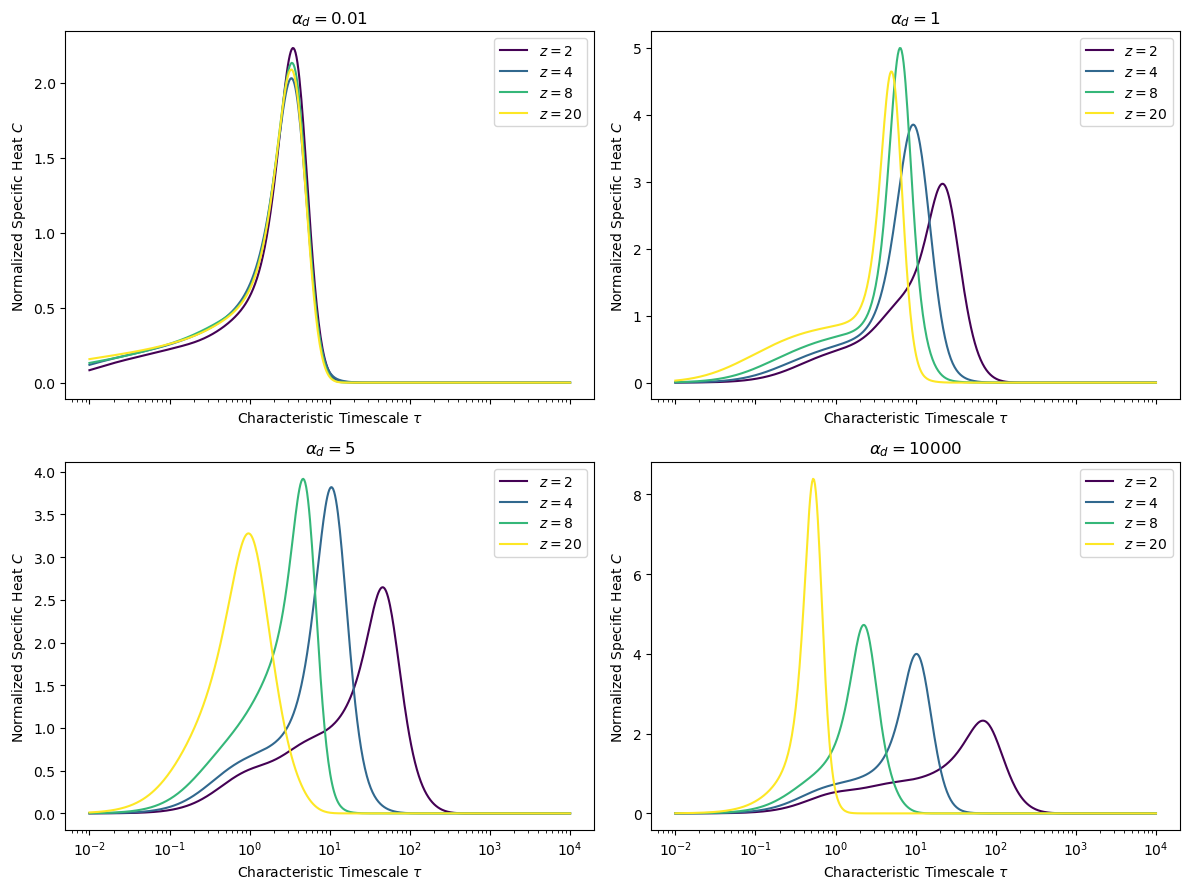

In [22]:
N, R = 1000, 20
alphas = [0.01, 1.0, 5.0, 10000.0]
zs = [2.0, 4.0, 8.0, 20.0]
taus = np.logspace(-2, 4, 500)
colors = plt.cm.viridis(np.linspace(0, 1, len(zs)))

fig, axes = plt.subplots(2, 2, figsize=(12, 9), sharex=True)
for ax, ad in zip(axes.flat, alphas):
    for z, c in zip(zs, colors):
        rng = np.random.default_rng(0)
        C = np.zeros(len(taus))
        for _ in range(R):
            adj, _ = nb_graph(N, ad, z, rng)
            lam = giant_spectrum(adj)
            MU = np.exp(-np.outer(taus, lam)); MU /= MU.sum(axis=1, keepdims=True)
            C += taus**2 * ((MU @ lam**2) - (MU @ lam)**2) #/ len(lam)
        ax.semilogx(taus, C/R, color=c, label=rf'$z={z:g}$')
    ax.set_title(rf'$\alpha_d={ad:g}$')
    ax.legend()
for ax in axes.flat:
    ax.set_xlabel(r'Characteristic Timescale $\tau$')
    ax.set_ylabel(r'Normalized Specific Heat $C$')
    
fig.tight_layout()


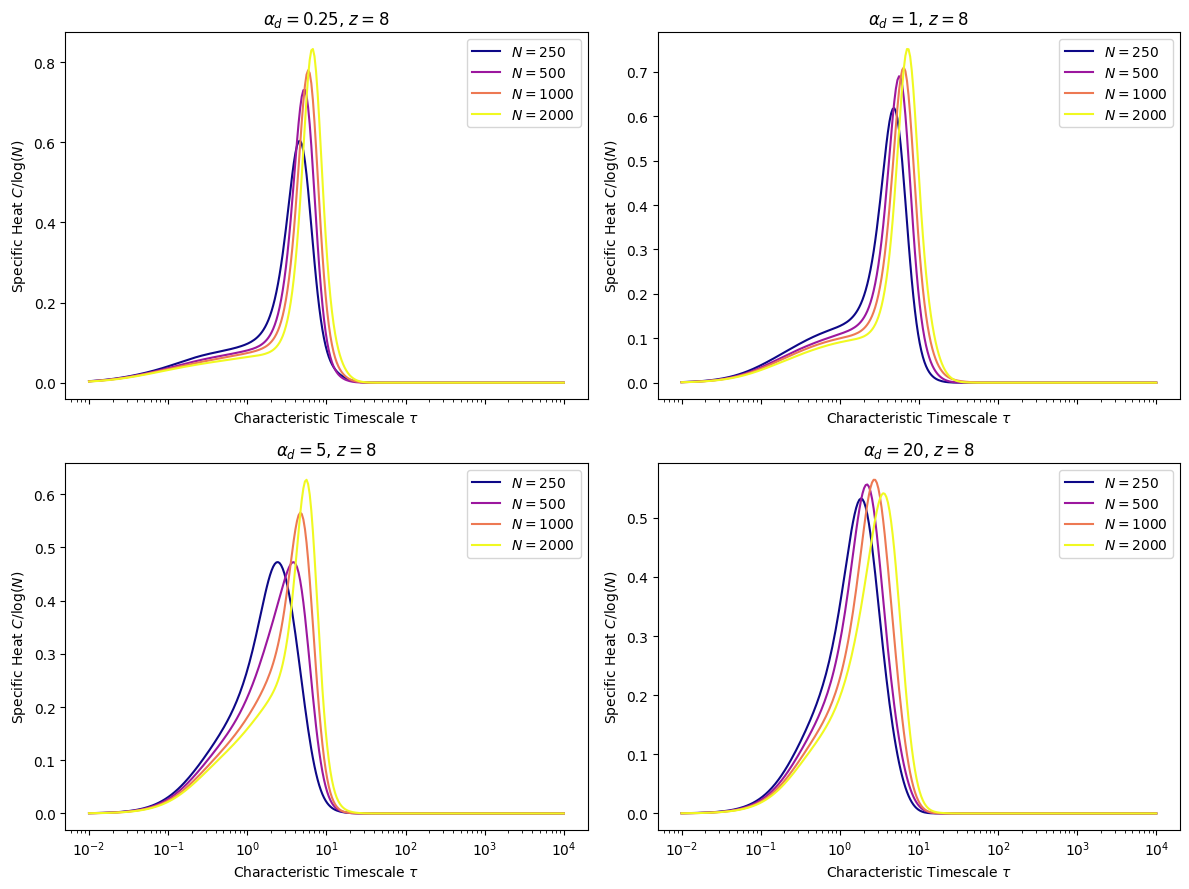

In [5]:
N_list = [250, 500, 1000, 2000]
R, z = 10, 8.0
alphas = [0.25, 1.0, 5.0, 20.0]
taus = np.logspace(-2, 4, 300)
colors = plt.cm.plasma(np.linspace(0, 1, len(N_list)))

fig, axes = plt.subplots(2, 2, figsize=(12, 9), sharex=True)
for ax, ad in zip(axes.flat, alphas):
    for N, c in zip(N_list, colors):
        rng = np.random.default_rng(0)
        C = np.zeros(len(taus))
        for _ in range(R):
            adj, _ = nb_graph(N, ad, z, rng)
            lam = giant_spectrum(adj)
            MU = np.exp(-np.outer(taus, lam)); MU /= MU.sum(axis=1, keepdims=True)
            C += taus**2 * ((MU @ lam**2) - (MU @ lam)**2)
        ax.semilogx(taus, C/R/np.log(N), color=c, label=rf'$N={N:g}$')
    ax.set_title(rf'$\alpha_d={ad:g}$, $z={z:g}$')
    ax.legend()
for ax in axes.flat:
    ax.set_xlabel(r'Characteristic Timescale $\tau$')
    ax.set_ylabel(r'Specific Heat $C/\log(N)$')
fig.tight_layout()


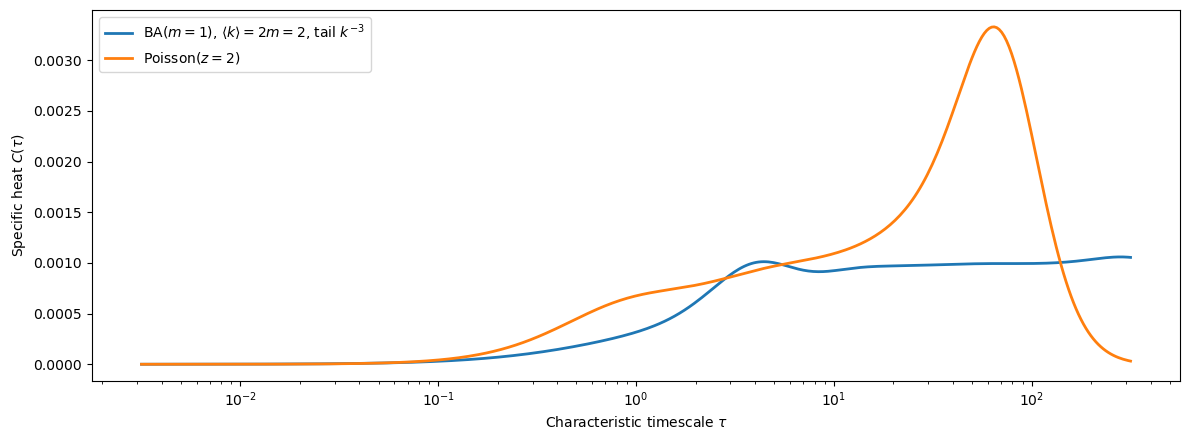

In [23]:
# Specific heat C(tau) vs tau: Barabasi-Albert preferential attachment vs ER (Poisson).
N, R, m = 1000, 10, 1   # BA: m links per new node -> mean degree 2m = 20, tail P(k) ~ k^-3.
z = 2 * m

def spectrum(G):
    return np.linalg.eigvalsh(nx.laplacian_matrix(G).toarray())

taus = np.logspace(-2.5, 2.5, 400)
def C_curve(lam):
    MU = np.exp(-np.outer(taus, lam)); MU /= MU.sum(axis=1, keepdims=True)
    return taus**2 * ((MU @ lam**2) - (MU @ lam)**2)/len(lam)

fig, axes = plt.subplots(1, 1, figsize=(12, 4.5), sharey=True)

# Barabasi-Albert preferential attachment
C = np.zeros(len(taus))
for _ in range(R):
    C += C_curve(spectrum(nx.barabasi_albert_graph(N, m, seed=_)))
axes.semilogx(taus, C/R, lw=2.0, color='C0',
                 label=rf'BA($m={m}$), $\langle k\rangle=2m={z:g}$, tail $k^{{-3}}$')

# ER: Poisson degree config model
def config_adj(degrees, rng):
    stubs = np.repeat(np.arange(N), degrees); rng.shuffle(stubs)
    n_edges = len(stubs)//2
    u = stubs[:2*n_edges:2]; v = stubs[1:2*n_edges:2]
    mask = u != v
    rows = np.concatenate([u[mask], v[mask]]); cols = np.concatenate([v[mask], u[mask]])
    return sparse.csr_matrix((np.ones(len(rows), dtype=np.float32), (rows, cols)), shape=(N, N))

rng = np.random.default_rng(0)
C = np.zeros(len(taus))
for _ in range(R):
    adj = config_adj(poisson.rvs(z, size=N, random_state=rng), rng)
    G = nx.from_scipy_sparse_array(adj)
    gc = max(nx.connected_components(G), key=len)
    C += C_curve(np.linalg.eigvalsh(nx.laplacian_matrix(G.subgraph(gc)).toarray()))
axes.semilogx(taus, C/R, lw=2.0, color='C1', label=rf'Poisson$(z={z:g})$')
#axes.semilogx(taus, C/R, lw=2.0, color='C1', label=rf'BA($m={m}$), $\langle k\rangle=2m={z:g}$, tail $k^{{-3}}$')


axes.set_xlabel(r'Characteristic timescale $\tau$')
axes.set_ylabel(r'Specific heat $C(\tau)$')
axes.legend(fontsize=10)
fig.tight_layout()
